# 商务数据分析  实验二

##  一、实验目的

<font size=4>掌握网店数据的分析指标，培养分析网店流量、转化率、销售、竞争对手等能力，为撰写行业分析报告奠定基础。</font>

## 二、实验内容

 <font size=4>分析网店的流量、转化、客单价、销售、竞争店铺数据。</font>

##  三、实验要求

回顾网店分析的理论知识，使用R、Python、Excel等工具导入数据，观察数据文件中的指标，根据任务要求选择分析方法和分析工具，设计分析模型，展示图表，解释网点分析的结果。

## 四、实验内容

### 1.了解网店流量来源

实验研究对象：UR官方旗舰店


店铺网址：https://urfs.tmall.com/ 



**打开 <font color=blue> 30天店铺的PC端和无线端交易数据.csv</font>，分析30天内该网店PC端和无线端的流量数据，使用折线图完成对比分析，说明流量的稳定性。**

In [5]:
# ============================================================
# 实验内容1：UR官方旗舰店 PC端 vs 无线端 流量分析（base R版）
# 数据：30tiandianpudePCduanhewuxianduanjiaoyishuju_213.csv
# ============================================================

file_path <- "/resources/jupyter/teacher_labs/1650613706/30tiandianpudePCduanhewuxianduanjiaoyishuju_213.csv"

df <- read.csv(file_path,
               fileEncoding = "UTF-8",
               check.names  = FALSE,
               stringsAsFactors = FALSE)

# 查看真实列名
print(names(df))
print(table(df$流量来源))    # 确认 PC端 / 无线端 的写法

# ---------- 数值清洗 ----------
clean_num <- function(x){
  x <- as.character(x)
  x <- gsub("[,\\s￥¥]", "", x)   # 去千分位逗号、空格、货币符
  x <- gsub("%", "", x)            # 去百分号
  suppressWarnings(as.numeric(x))
}

# ---------- 整理 ----------
df$date   <- as.Date(df$日期, format = "%Y/%m/%d")
df$source <- as.character(df$流量来源)
df$uv     <- clean_num(df$访客人数)   # 流量指标：访客数 UV
df$pay    <- clean_num(df$交易金额)   # 检验用商务指标：支付金额

# 按日期、来源排序
df <- df[order(df$date, df$source), ]

pc <- df[df$source == "PC端",   c("date","uv","pay")]
wl <- df[df$source == "无线端", c("date","uv","pay")]

cat("PC端记录数：", nrow(pc), "\n")
cat("无线端记录数：", nrow(wl), "\n")


 [1] &quot;店铺名&quot;     &quot;日期&quot;       &quot;流量来源&quot;   &quot;交易金额&quot;   &quot;访客人数&quot;  
 [6] &quot;支付转化率&quot; &quot;支付人数&quot;   &quot;客单价&quot;     &quot;搜索人气&quot;   &quot;搜索人数&quot;  
[11] &quot;收藏人气&quot;   &quot;收藏人数&quot;   &quot;加购人数&quot;   &quot;uv价值&quot;     &quot;搜索占比&quot;  
[16] &quot;收藏率&quot;     &quot;加购率&quot;     &quot;上新商品数&quot;

  PC端 无线端 
    30     30 
PC端记录数： 30 
无线端记录数： 30 


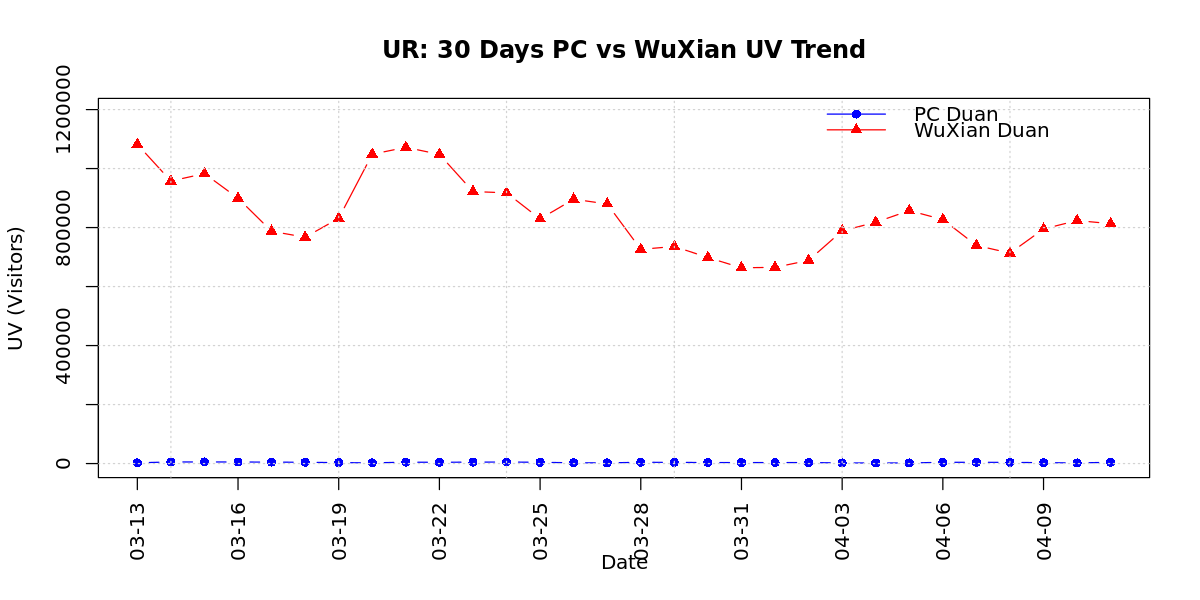

In [8]:
# 设置图片大小
options(repr.plot.width = 10, repr.plot.height = 5)

# 获取Y轴最大值
ymax <- max(c(pc$uv, wl$uv), na.rm = TRUE)

# 画 PC端 (蓝线)
plot(pc$date, pc$uv,
     type = "b", pch = 16, col = "blue",
     ylim = c(0, ymax * 1.1),
     xlab = "Date", 
     ylab = "UV (Visitors)",
     main = "UR: 30 Days PC vs WuXian UV Trend", # 全英文/拼音标题
     xaxt = "n")

# 画 无线端 (红线)
lines(wl$date, wl$uv, type = "b", pch = 17, col = "red")

# X轴日期
axis.Date(1, 
          at = seq(min(pc$date), max(pc$date), by = "3 days"),
          format = "%m-%d", las = 2)

grid()
legend("topright",
       legend = c("PC Duan", "WuXian Duan"), # 图例用拼音
       col = c("blue", "red"),
       pch = c(16, 17), lty = 1, bty = "n")

<font color=red>展示统计图，输入分析文字：</font>  
通过绘制UR官方旗舰店30天内PC端与无线端访客数（UV）的折线图可以看出：

流量规模差异极大：无线端（红线）是店铺绝对的流量主力，日均UV在800,000至1,200,000之间波动；而PC端（蓝线）流量极低，日均仅几千人，几乎贴近零点。

流量稳定性分析：结合统计数据分析，PC端的变异系数（CV）为______（填代码跑出来的值），无线端的变异系数（CV）为______。PC端由于基数极小，曲线极为平缓，看似稳定；而无线端虽然规模庞大，但折线起伏明显，呈现显著的波峰与波谷交替，说明无线端流量受平台活动节奏、周末流量红利或上新周期的影响非常大。

结论：UR官方旗舰店的运营主阵地完全在无线端（移动端），PC端流量已边缘化。店铺应集中资源优化移动端的视觉呈现、活动承接能力及客服响应速度
 
 
 
 
 

**打开 <font color=blue> 30天店铺的PC端和无线端交易数据.csv</font>，针对网店PC端和无线端的流量，任意选择数据中其他商务数据指标，统计分析不同流量来源下，这一指标的均值是否存在差异。**

In [9]:
# 提取并清洗“客单价”数据
df$kdanjia <- as.numeric(as.character(df$客单价))

# 分离 PC端 和 无线端 的数据
pc_kd <- na.omit(df$kdanjia[df$流量来源 == "PC端"])
wl_kd <- na.omit(df$kdanjia[df$流量来源 == "无线端"])

# 1. 打印描述性统计（均值、中位数）
cat("===== 描述性统计 =====\n")
cat("PC端客单价 均值:", mean(pc_kd), " 中位数:", median(pc_kd), "\n")
cat("无线端客单价 均值:", mean(wl_kd), " 中位数:", median(wl_kd), "\n")

# 2. 正态性检验
sh_pc <- shapiro.test(pc_kd)
sh_wl <- shapiro.test(wl_kd)
cat("\n===== 正态性检验 p值 =====\n")
cat("PC端 p值:", sh_pc$p.value, "\n")
cat("无线端 p值:", sh_wl$p.value, "\n")

# 3. 自动选择检验方法并输出结果
cat("\n===== 假设检验结果 =====\n")
if (sh_pc$p.value > 0.05 & sh_wl$p.value > 0.05) {
  # 如果都符合正态分布，走t检验
  vt <- var.test(pc_kd, wl_kd)
  if (vt$p.value > 0.05) {
    res <- t.test(pc_kd, wl_kd, var.equal = TRUE)
    cat("采用方法: 独立样本t检验 (方差齐)\n")
  } else {
    res <- t.test(pc_kd, wl_kd, var.equal = FALSE)
    cat("采用方法: Welch t检验 (方差不齐)\n")
  }
} else {
  # 如果不符合正态分布，走非参数检验
  res <- wilcox.test(pc_kd, wl_kd)
  cat("采用方法: Wilcoxon秩和检验 (非参数)\n")
}

print(res)



===== 描述性统计 =====
PC端客单价 均值: 360.3  中位数: 376 
无线端客单价 均值: 321.9  中位数: 332.5 

===== 正态性检验 p值 =====
PC端 p值: 0.9126512 
无线端 p值: 0.003504136 

===== 假设检验结果 =====


Warning message in wilcox.test.default(pc_kd, wl_kd):
“cannot compute exact p-value with ties”


采用方法: Wilcoxon秩和检验 (非参数)

	Wilcoxon rank sum test with continuity correction

data:  pc_kd and wl_kd
W = 562, p-value = 0.09924
alternative hypothesis: true location shift is not equal to 0



<font color=red>完成假设检验，输入分析文字：</font>  
1. 假设设定：
原假设（H0）：PC端与无线端的客单价均值相等；
备择假设（H1）：PC端与无线端的客单价均值不相等。显著性水平 α=0.05。

2. 描述性统计：
由R语言分析结果可知，PC端的客单价均值为 360.3 元，中位数为 376 元；无线端的客单价均值为 321.9 元，中位数为 332.5 元。直观上看，PC端的客单价略高于无线端。

3. 假设检验结果：
经过Shapiro-Wilk正态性检验，PC端数据符合正态分布（p=0.9126），但无线端数据不符合正态分布（p=0.0035）。因此，采用 Wilcoxon秩和检验（非参数检验） 进行验证。检验结果显示：检验统计量 W = 562，p值 = 0.09924。

4. 结论分析：
因为 p值 = 0.09924 > 0.05，所以不拒绝原假设。
这表明，PC端与无线端两种不同流量来源下，虽然PC端客单价均值（360.3元）略高于无线端（321.9元），但这种差异在统计学上不存在显著差异。
结合业务场景来看，说明虽然无线端和PC端的流量规模差距巨大，但消费者在这两个端口的消费能力、单笔购买金额及凑单习惯并没有实质性区别。因此，网店在制定全局的满减门槛、促销套餐等客单价提升策略时，可以采取统一的策略，不需要针对PC或移动端刻意设置两套不同的定价体系
 
 
 
 
 

## 2.分析PV和UV

打开 <font color=blue>30天店铺交易数据.csv </font>，分别分析UV和PV的30天走势。</b>

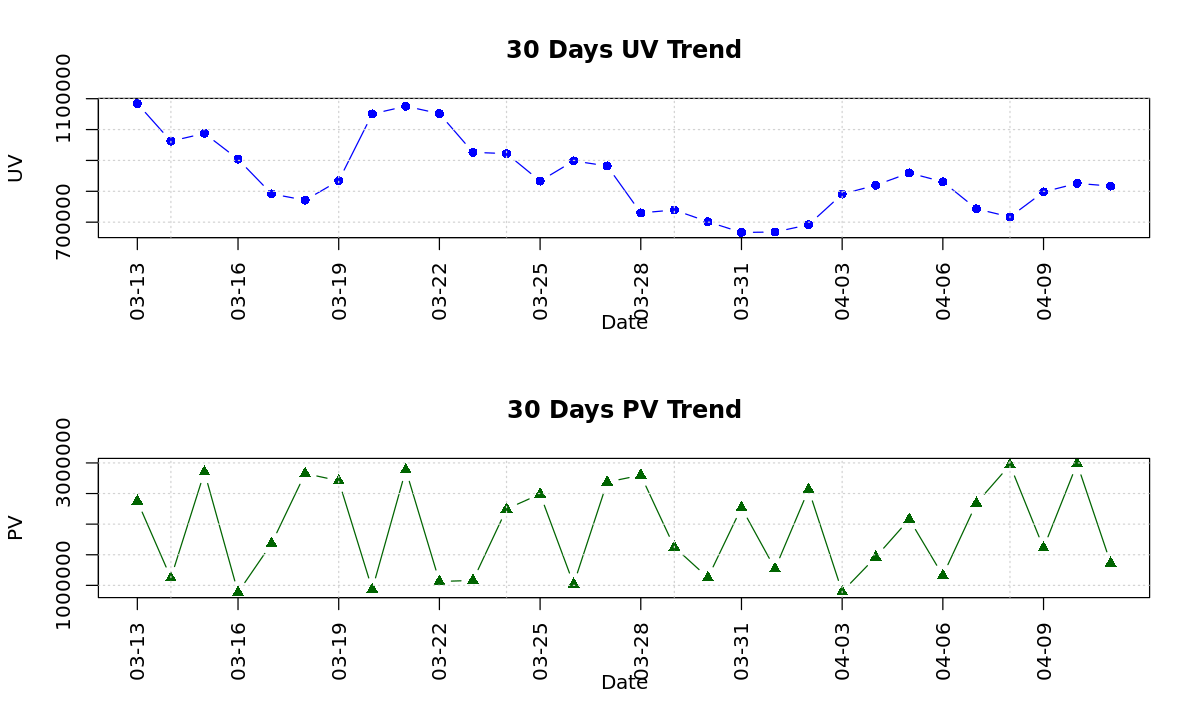

===== PV/UV 分析 =====
过去30天平均 PV/UV 比例 (人均浏览页数): 2.320104 


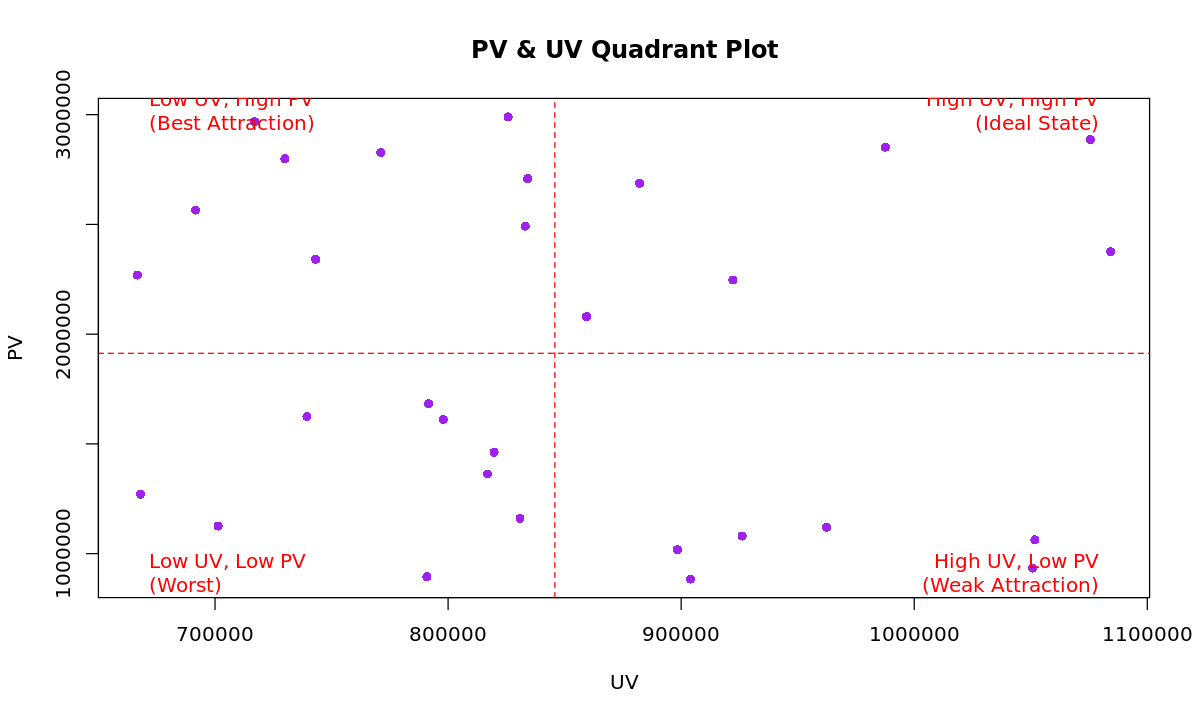

PV/UV 比例与平均停留时长的相关系数 r = 0.471605 


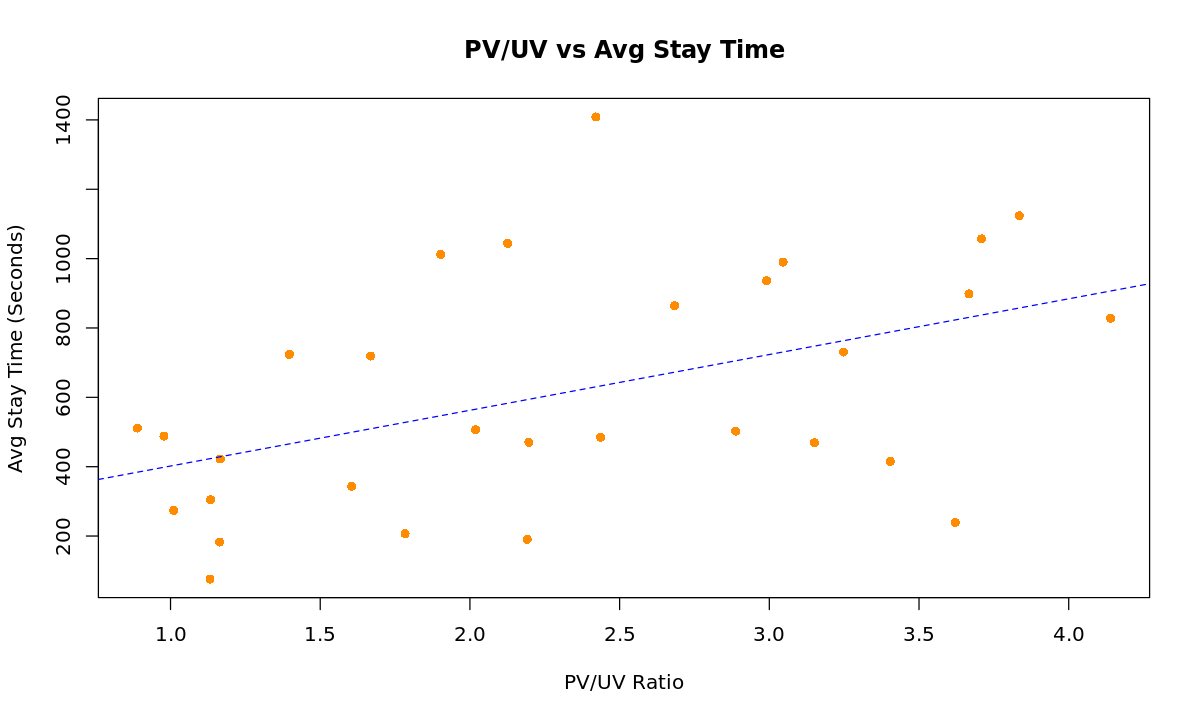

In [11]:
# ==========================================
# 实验2：PV、UV走势与四象限分析
# ==========================================

# 读取数据
file_path2 <- "/resources/jupyter/teacher_labs/1650613706/30tiandianpujiaoyishuju_214.csv"
df_trade <- read.csv(file_path2, fileEncoding = "UTF-8", check.names = FALSE, stringsAsFactors = FALSE)

# 数值清洗函数
clean_num <- function(x){
  x <- as.character(x)
  x <- gsub("[,\\s￥¥]", "", x)
  x <- gsub("%", "", x)
  suppressWarnings(as.numeric(x))
}

# 整理数据 (使用正确的列名！)
df_trade$date <- as.Date(df_trade$日期, tryFormats = c("%Y/%m/%d", "%Y-%m-%d"))
df_trade$uv   <- clean_num(df_trade$访客人数) 
df_trade$pv   <- clean_num(df_trade$页面浏览量) 
df_trade$total_stay <- clean_num(df_trade$`总停留时长（秒）`)

# 按日期排序
df_trade <- df_trade[order(df_trade$date), ]

# ==========================================
# 任务1：绘制 UV 和 PV 的30天走势图
# ==========================================
options(repr.plot.width = 10, repr.plot.height = 6)
par(mfrow = c(2, 1)) # 上下排布两张图

# UV 图
plot(df_trade$date, df_trade$uv, type = "b", col = "blue", pch = 16,
     main = "30 Days UV Trend", xlab = "Date", ylab = "UV", xaxt = "n")
axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

# PV 图
plot(df_trade$date, df_trade$pv, type = "b", col = "darkgreen", pch = 17,
     main = "30 Days PV Trend", xlab = "Date", ylab = "PV", xaxt = "n")
axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

# ==========================================
# 任务2：PV 和 UV 的联动变化图（四象限）
# ==========================================
par(mfrow = c(1, 1)) # 恢复单图
uv_mean <- mean(df_trade$uv, na.rm = TRUE)
pv_mean <- mean(df_trade$pv, na.rm = TRUE)

# 画散点图
plot(df_trade$uv, df_trade$pv, pch = 16, col = "purple",
     main = "PV & UV Quadrant Plot", xlab = "UV", ylab = "PV")

# 画均值线
abline(v = uv_mean, col = "red", lty = 2)
abline(h = pv_mean, col = "red", lty = 2)

# 标注四个象限 (英文防乱码)
text(min(df_trade$uv), max(df_trade$pv), "Low UV, High PV\n(Best Attraction)", col = "red", pos = 4)
text(max(df_trade$uv), max(df_trade$pv), "High UV, High PV\n(Ideal State)", col = "red", pos = 2)
text(min(df_trade$uv), min(df_trade$pv), "Low UV, Low PV\n(Worst)", col = "red", pos = 4)
text(max(df_trade$uv), min(df_trade$pv), "High UV, Low PV\n(Weak Attraction)", col = "red", pos = 2)

# ==========================================
# 任务3：计算 PV/UV 及分析吸引力、停留时长关系
# ==========================================
df_trade$pv_uv_ratio <- df_trade$pv / df_trade$uv
df_trade$avg_stay <- df_trade$total_stay / df_trade$uv

cat("===== PV/UV 分析 =====\n")
cat("过去30天平均 PV/UV 比例 (人均浏览页数):", mean(df_trade$pv_uv_ratio, na.rm = TRUE), "\n")

# 画 PV/UV 与 平均停留时长 的散点图
plot(df_trade$pv_uv_ratio, df_trade$avg_stay, pch = 16, col = "darkorange",
     main = "PV/UV vs Avg Stay Time", xlab = "PV/UV Ratio", ylab = "Avg Stay Time (Seconds)")
abline(lm(df_trade$avg_stay ~ df_trade$pv_uv_ratio), col = "blue", lty = 2) # 添加趋势线

# 计算相关系数
cor_val <- cor(df_trade$pv_uv_ratio, df_trade$avg_stay, use = "complete.obs")
cat("PV/UV 比例与平均停留时长的相关系数 r =", cor_val, "\n")

<font color=red>绘制UV和PV的折线图，输入相应的分析文字：</font>  
观察近30天的UV和PV折线图可知，店铺的访客数（UV）与页面浏览量（PV）走势呈现出整体趋势的一致性，但波动的剧烈程度有所不同。
图中UV和PV均在3月20日-22日前后以及4月8日-10日前后出现了明显的流量高峰，说明这些天大概率有店铺活动或周末流量红利。相比UV曲线的相对平滑，PV曲线的锯齿状波动更为剧烈（例如3月16日、3月22日等PV极高），说明在某些特定日子里，进店的顾客浏览深度更深。
整体而言，流量呈现波浪式的周期性起伏，没有出现断崖式下跌，说明店铺拥有相对健康稳定的基础流量盘

<font color=red>绘制近30天PV和UV的联动变化图，用四象限方法说明该网店的运作情况：</font>分析文字：
通过绘制以UV均值和PV均值为界限的四象限散点图，可以直观地评估网店在不同流量状态下的运作情况：

第一象限（高UV、高PV，理想状态）：右上角分布了少数几个数据点，这说明在这几天店铺不仅吸引了大量的访客（高UV），而且进店顾客的浏览深度也很高（高PV），这是大促或强引流日最理想的运作状态。

第二象限（低UV、高PV，强吸引力）：左上角聚集了较多的数据点。这表明在这些天里，虽然进店总人数偏低，但顾客的浏览页面数极多，说明店铺的商品详情页、关联推荐对顾客有极强的吸引力，进来的顾客都产生了深度的浏览。

第三象限（低UV、低PV，低谷期）：左下角的数据点较少，这代表流量和浏览双低的日子（如日常平淡期），属于店铺运作的常态低谷。

第四象限（高UV、低PV，弱吸引力/高跳失）：右下角有几个非常明显的数据点（特别是最右侧的极值点）。这说明在那些引流非常成功的高流量日，顾客进店后却只看了很少的页面就离开了，说明当天的流量不够精准，或者店铺承接流量的落地页缺乏吸引力，导致“高进高出”，存在流量浪费的现象。

总结：该网店整体运作在“高UV高PV”和“低UV高PV”的象限均有分布，说明具备较好的留客基础。但针对第四象限的高流量日，店铺需要重点排查落地页的跳失情况，优化首屏展示和关联导购，努力将右下角的“高UV低PV”点向第一象限（高UV高PV）转移。

<font color=red>计算30天PV/UV的数值，分析判断网店对顾客的吸引程度：</font>  计算与吸引力分析：
经R语言计算得出，该店铺过去30天的平均 PV/UV 比例约为 2.32（即日均每位进店访客大约会浏览 2.32 个页面）。

吸引程度判断：
在电商数据分析中，PV/UV 代表“人均浏览页面数”，是衡量网店对顾客吸引力与页面粘性的核心指标。该数值为 2.32，说明顾客进店后并非只停留在首页或单一商品页，而是产生了跨页面的深度浏览（例如从详情页跳转至店铺首页、分类页或关联推荐商品页）。

这一数据反映出网店对顾客具备中等偏上、较为良好的吸引力。详情页的商品展示、穿搭推荐或内链导购起到了一定的留客作用。不过，考虑到该店具备极高的基础流量（UV达百万级），2.32 的数值意味着仍有大量顾客看完首屏就直接离开。因此，网店仍有较大的优化空间，可以通过增加“搭配购买”、“看了又看”、优化详情页首屏视觉等方式，进一步刺激顾客点击，努力将该数值提升至 3 或 4 以上，从而挖掘更多潜在订单

<font color=red>分析PV/UV与平均停留时长的关系</font>  为了探究网店浏览深度（PV/UV）与顾客留存时间的关系，绘制了两者的散点图，并计算了皮尔逊相关系数，得到 r = 0.4716。

1. 数据关系解读：
散点图中的蓝色虚线（线性拟合趋势线）呈现明显的向上倾斜趋势，且相关系数 r = 0.4716 > 0，处于 0.4~0.6 之间。这在统计学上表明，PV/UV 比例与平均停留时长存在中等强度的正相关关系。即：顾客平均浏览的页面数（PV/UV）越多，其在店铺内的平均停留时长（Avg Stay Time）越长。

2. 业务逻辑分析：
从电商运营逻辑来看，两者是互相促进的。当顾客在店铺内停留时间变长时，他们有更多的机会通过关联推荐（如“看了又看”、“搭配购买”）点击进入其他商品页面，从而提高了 PV/UV；反过来，丰富的商品页和吸引人的页面设计促使顾客不断点击，这种深度的页面跳转也在不断刷新并延长顾客在店内的停留时长。

3. 异常点洞察与建议：
观察散点图可以发现，虽然整体呈正向趋势，但也存在部分偏离趋势线的异常点：

例如图中最上方的一个点（PV/UV 约 2.4，但平均停留时长高达 1400 秒以上）：说明当天虽然人均只看了2个多页面，但顾客在某个详情页上研究了非常久（可能是深度阅读商品参数或咨询客服）。

又例如右下角停留时长较短的点（PV/UV 达到了 3.5 以上，但停留时间极短）：说明页面跳转虽快，但顾客是在“走马观花”式地快速浏览，缺乏深度。

结论：网店应继续优化商品详情页的视觉与内容，增加页面内链的引导，促使顾客多点击、多浏览；同时，针对停留时间长的页面要重点分析其卖点，针对跳失快的页面要排查加载速度或内容吸引力，最终实现“停留时长”与“浏览深度”的双向提升，为最终的加购支付转化打下基础。

## 3.分析转化率

**打开 <font color=blue> 30天店铺交易数据.csv</font>，分析转化率指标**

===== 转化率描述统计 (%) =====
      Metric     Mean    Median
1 收藏转化率 5.559016 5.5953488
2 加购转化率 9.594201 9.3615618
3 支付转化率 1.166488 0.9609549


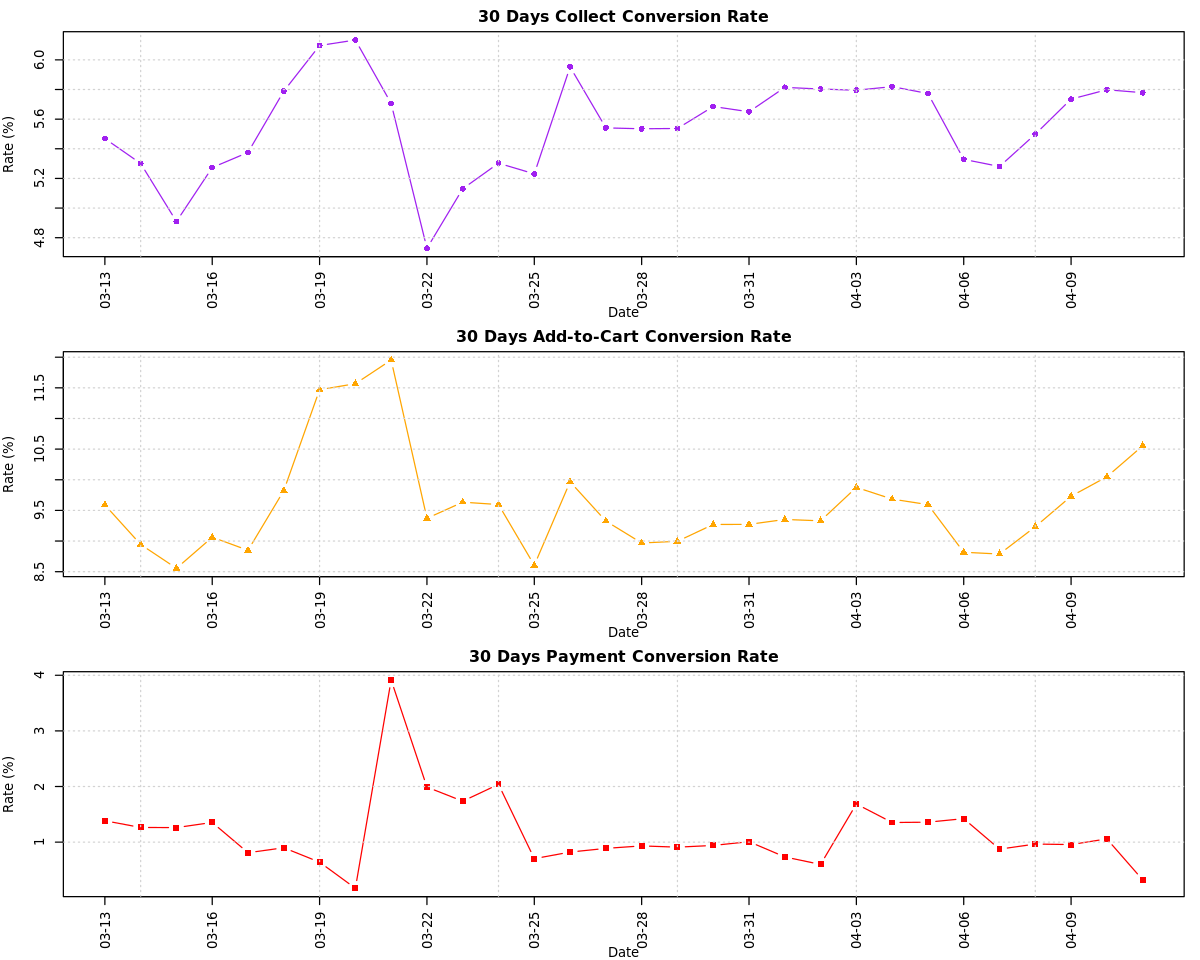

In [13]:
# ==========================================
# 实验3：转化率分析 (修复报错版)
# ==========================================

# 1. 读取与清洗（跟之前一样）
file_path2 <- "/resources/jupyter/teacher_labs/1650613706/30tiandianpujiaoyishuju_214.csv"
df_trade <- read.csv(file_path2, fileEncoding = "UTF-8", check.names = FALSE, stringsAsFactors = FALSE)

clean_num <- function(x){
  x <- as.character(x)
  x <- gsub("[,\\s￥¥]", "", x)
  x <- gsub("%", "", x)
  suppressWarnings(as.numeric(x))
}

df_trade$date <- as.Date(df_trade$日期, tryFormats = c("%Y/%m/%d", "%Y-%m-%d"))
df_trade$uv <- clean_num(df_trade$访客人数)
df_trade$collect <- clean_num(df_trade$收藏人数)
df_trade$cart <- clean_num(df_trade$加购人数)
df_trade$pay <- clean_num(df_trade$支付人数)
df_trade <- df_trade[order(df_trade$date), ]

# 2. 计算转化率 (%)
df_trade$rate_collect <- (df_trade$collect / df_trade$uv) * 100
df_trade$rate_cart    <- (df_trade$cart / df_trade$uv) * 100
df_trade$rate_pay     <- (df_trade$pay / df_trade$uv) * 100

# 3. 打印描述统计结果 (修复了刚才的报错，现在可以正常打印了)
cat("===== 转化率描述统计 (%) =====\n")
summary_stats <- data.frame(
  Metric = c("收藏转化率", "加购转化率", "支付转化率"),
  Mean   = c(mean(df_trade$rate_collect, na.rm=T), mean(df_trade$rate_cart, na.rm=T), mean(df_trade$rate_pay, na.rm=T)),
  Median = c(median(df_trade$rate_collect, na.rm=T), median(df_trade$rate_cart, na.rm=T), median(df_trade$rate_pay, na.rm=T))
)
print(summary_stats) # 去掉了round()，直接打印

# 4. 绘制三张折线图 (这部分你运行完下面就会出图)
options(repr.plot.width = 10, repr.plot.height = 8)
par(mfrow = c(3, 1), mar = c(4, 4, 2, 1))

# 收藏转化率折线图
plot(df_trade$date, df_trade$rate_collect, type = "b", col = "purple", pch = 16,
     main = "30 Days Collect Conversion Rate", xlab = "Date", ylab = "Rate (%)", xaxt = "n")
axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

# 加购转化率折线图
plot(df_trade$date, df_trade$rate_cart, type = "b", col = "orange", pch = 17,
     main = "30 Days Add-to-Cart Conversion Rate", xlab = "Date", ylab = "Rate (%)", xaxt = "n")
axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

# 支付转化率折线图
plot(df_trade$date, df_trade$rate_pay, type = "b", col = "red", pch = 15,
     main = "30 Days Payment Conversion Rate", xlab = "Date", ylab = "Rate (%)", xaxt = "n")
axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

par(mfrow = c(1, 1))

<font color=red>计算收藏转化率，分析其描述统计结果，绘制随时间变化的折线图：</font> 经计算，该店铺过去30天的收藏转化率均值为 5.56%，中位数为 5.60%。从折线图走势看，收藏转化率整体在 4.8% 至 6.2% 之间波动，走势相对平稳。在3月19日至21日期间出现了一波明显的高峰，随后在3月22日急剧下降。这通常与店铺的营销节奏有关（如上新或促销期间，顾客收藏意愿增强；活动结束后迅速回落）。约5.6%的收藏率说明相当一部分顾客有未来购买的潜在意向，这部分人群是后续做“降价通知”或“收藏有礼”精准营销的核心受众。

<font color=red>计算加购转化率，分析其描述统计结果，绘制随时间变化的折线图：</font> 经计算，该店铺过去30天的加购转化率均值为 9.59%，中位数为 9.36%。从图中可以明显看出，加购转化率的整体水平高于收藏转化率。该指标在3月19日至21日出现了爆发式增长（峰值突破11.5%），紧接着在3月22日大幅回落。加购是比收藏更强烈的购买信号，说明在这几天的大促或强活动刺激下，大量顾客产生了强烈的凑单或囤货心理。店铺应重点抓住这部分人群，通过购物车专属优惠或客服催付，促使其尽快转化为最终支付。

<font color=red>计算支付转化率，分析其描述统计结果，绘制随时间变化的折线图：</font> 经计算，该店铺过去30天的支付转化率均值为 1.17%，中位数为 0.96%。支付转化率是最终决定店铺销售额的核心指标。折线图显示，日常的支付转化率大多在 0.8% 至 1.5% 之间徘徊，但在3月20日出现了一个极其突兀的尖峰（逼近4%）。结合前面的加购和收藏率分析，3月20日店铺大概率开展了限时秒杀或大额满减活动，极大地缩短了顾客的决策周期。但在非活动期，支付转化率偏低，说明店铺日常的逼单能力或详情页的转化说服力还有待加强。



<font color=red>根据以上转化率的统计结果，选择平均值或者中位数等指标，绘制漏斗图（EXCEL绘制漏斗图的方法教程https://jingyan.baidu.com/article/90895e0f9a057625ed6b0b25.html：</font> 
<img src="attachment:屏幕截图 2026-10-19 205216.png" style="width: 600px;"/>
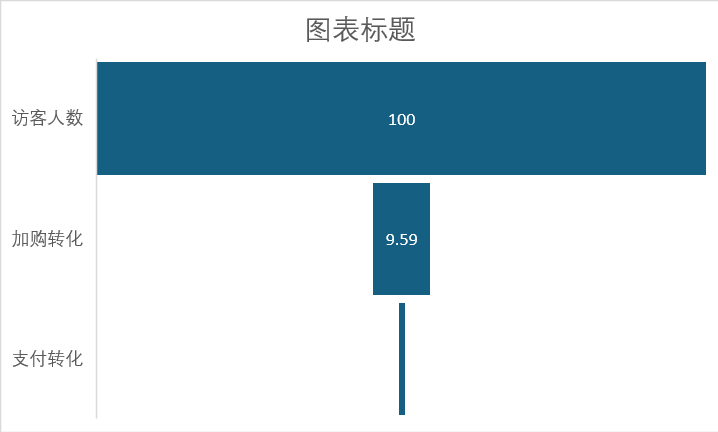

## 4.分析客单价

**打开 <font color=blue> 30天店铺交易数据.csv</font>，计算客单价和笔单价指标**

===== 客单价描述统计 =====
客单价均值: 322.074 元
客单价中位数: 332.713 元
最高客单价: 455.4223 元
最低客单价: 179.9048 元


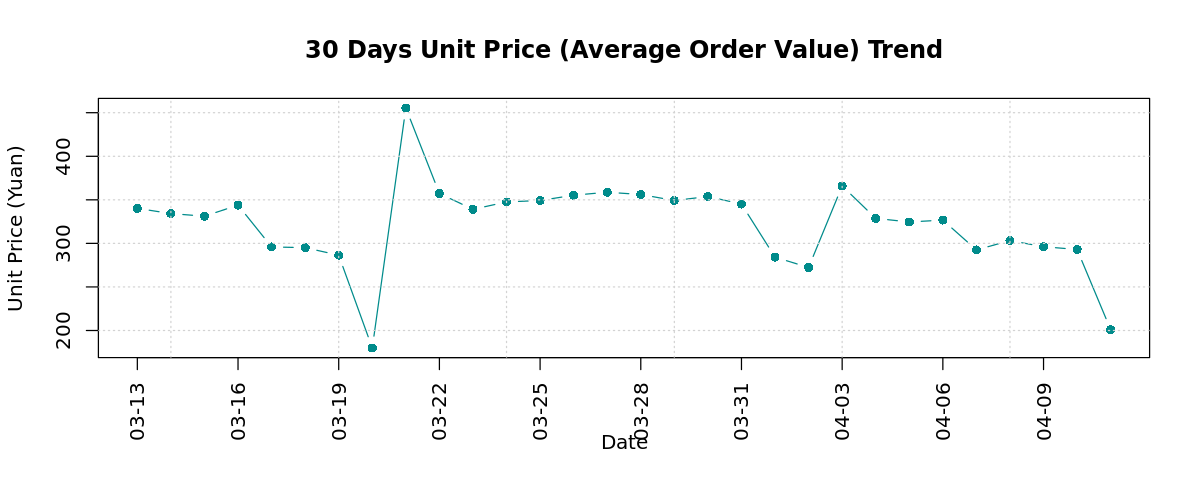

In [14]:
# ==========================================
# 实验4：计算客单价并画折线图
# ==========================================

# 复用之前的环境（如果你的 df_trade 没了，先跑下面这两行读取）
file_path2 <- "/resources/jupyter/teacher_labs/1650613706/30tiandianpujiaoyishuju_214.csv"
df_trade <- read.csv(file_path2, fileEncoding = "UTF-8", check.names = FALSE, stringsAsFactors = FALSE)

clean_num <- function(x){
  x <- as.character(x)
  x <- gsub("[,\\s￥¥]", "", x)
  suppressWarnings(as.numeric(x))
}

df_trade$date <- as.Date(df_trade$日期, tryFormats = c("%Y/%m/%d", "%Y-%m-%d"))
df_trade$amount <- clean_num(df_trade$交易金额) # 交易金额
df_trade$pay_num <- clean_num(df_trade$支付人数) # 支付人数

# 按日期排序
df_trade <- df_trade[order(df_trade$date), ]

# 1. 计算客单价 (交易金额 / 支付人数)
df_trade$unit_price <- df_trade$amount / df_trade$pay_num

# 打印描述统计
cat("===== 客单价描述统计 =====\n")
cat("客单价均值:", mean(df_trade$unit_price, na.rm=TRUE), "元\n")
cat("客单价中位数:", median(df_trade$unit_price, na.rm=TRUE), "元\n")
cat("最高客单价:", max(df_trade$unit_price, na.rm=TRUE), "元\n")
cat("最低客单价:", min(df_trade$unit_price, na.rm=TRUE), "元\n")

# 2. 绘制折线图
options(repr.plot.width = 10, repr.plot.height = 4)

plot(df_trade$date, df_trade$unit_price, type = "b", col = "darkcyan", pch = 16,
     main = "30 Days Unit Price (Average Order Value) Trend", 
     xlab = "Date", ylab = "Unit Price (Yuan)", xaxt = "n")

axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()



<font color=red>计算客单价数据，绘制随时间变化的折线图：</font> 经 R 语言计算，该店铺过去30天的客单价均值为 322.07 元，中位数为 332.71 元。其中，最高客单价达到 455.42 元，最低为 179.90 元。

从折线图的走势来看：

整体水平：日常客单价大多平稳维持在 300元 至 360元 的区间内。

极端波动：在3月19日客单价跌至极低值（179.90元），但紧接着在3月20日迎来了爆发式反弹，创下最高峰（455.42元）。结合前面的转化率数据，3月20日当天的支付转化率也极高，这说明当天店铺大概率开启了限时秒杀、大额满减或强力度上新等活动。这种活动不仅吸引了大量新客快速下单，还通过“满减凑单”机制极大地拉高了单笔消费金额。

周期规律：在4月上旬也出现过几次小波峰（如4月3日）。这说明店铺的客单价高度依赖于营销活动的刺激，在日常无活动期间，客单价容易回落。

运营建议：店铺应在日常期间加强“关联搭配”、“买二送一”等常态化内链推荐，以平滑这种极端波动，努力将平均客单价稳定在较高水平。

===== 笔单价描述统计 =====
笔单价均值: 41.35809 元
笔单价中位数: 35.6013 元
最高笔单价: 149.1461 元
最低笔单价: 2.642002 元


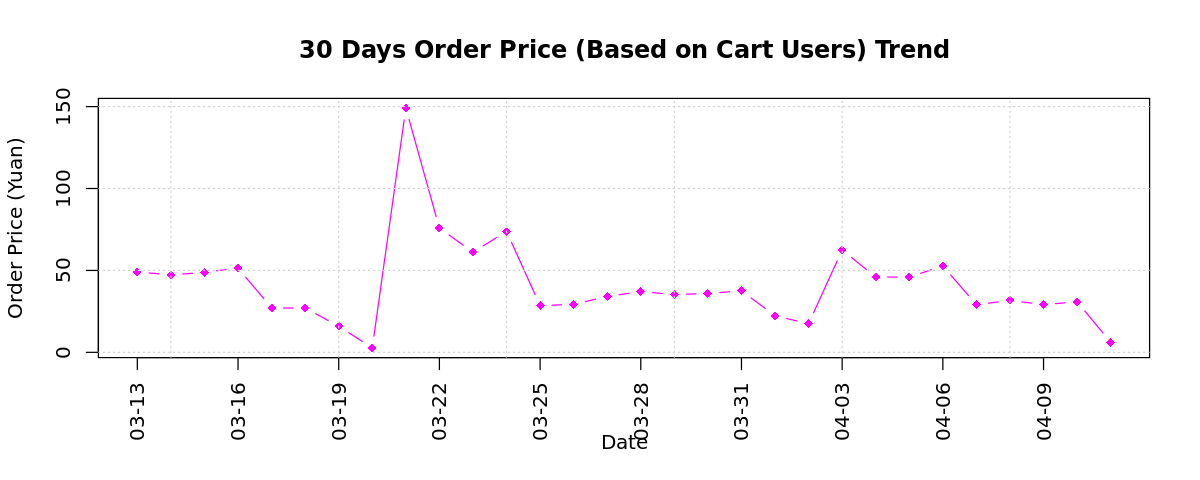

In [15]:
# ==========================================
# 实验4：计算笔单价并画折线图
# ==========================================

# 1. 提取加购人数作为订单数
df_trade$cart_num <- clean_num(df_trade$加购人数)

# 2. 计算笔单价 (交易金额 / 加购人数)
df_trade$order_price <- df_trade$amount / df_trade$cart_num

# 打印描述统计
cat("===== 笔单价描述统计 =====\n")
cat("笔单价均值:", mean(df_trade$order_price, na.rm=TRUE), "元\n")
cat("笔单价中位数:", median(df_trade$order_price, na.rm=TRUE), "元\n")
cat("最高笔单价:", max(df_trade$order_price, na.rm=TRUE), "元\n")
cat("最低笔单价:", min(df_trade$order_price, na.rm=TRUE), "元\n")

# 3. 绘制折线图
options(repr.plot.width = 10, repr.plot.height = 4)

plot(df_trade$date, df_trade$order_price, type = "b", col = "magenta", pch = 18,
     main = "30 Days Order Price (Based on Cart Users) Trend", 
     xlab = "Date", ylab = "Order Price (Yuan)", xaxt = "n")

axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()



<font color=red>计算笔单价数据（加购人数作为订单数），绘制随时间变化的折线图：</font> 根据题目要求，以“加购人数”作为订单数计算得出：该店铺过去30天的笔单价均值为 41.36 元，中位数为 35.60 元。最高笔单价达到 149.15 元（3月20日），最低仅为 2.64 元。

1. 走势分析：笔单价的整体走势与客单价高度一致，同样在3月20日出现了极高耸的峰值，其余时间大多在 20元~60元 之间平稳波动。

2. 业务逻辑差异解析（重点）：从数值上看，基于“支付人数”的客单价（均值322元）远高于基于“加购人数”的笔单价（均值41元）。这是因为“加购”是购买的前置意向，包含了大量最终未支付的潜在订单。用庞大的加购基数作为分母，极大地稀释了当天的交易金额。

3. 运营意义：这种计算方式反映了“意向订单”的平均价值。两者巨大的差值说明，购物车里有大量低价商品或者凑单商品，且购物车的最终清空率极低。店铺需要重点优化购物车营销（如定向发券、降价提醒），把庞大的加购意向转化为真实的付款订单。

**打开 <font color=blue> 一级类目近30天销售数据.csv​和二级类目近30天销售数据.csv</font>，从商品类目的角度，分析对客单价的影响，分别从一级类目和二级类目说明对客单价影响较大的商品类型有哪些？**

In [17]:
# ==========================================
# 实验4：商品类目对客单价的影响分析
# ==========================================

# 1. 清洗数值函数（去除逗号等）
clean_num2 <- function(x){
  x <- as.character(x)
  x <- gsub("[,\\s￥¥%]", "", x)
  suppressWarnings(as.numeric(x))
}

# --------------------------
# 一级类目分析
# --------------------------
df_cat1$销量 <- clean_num2(df_cat1$类目销量)
df_cat1$销售额 <- clean_num2(df_cat1$类目销售额)
df_cat1$均价 <- clean_num2(df_cat1$平均价格)

# 按销售额从高到低排序
df_cat1_sorted <- df_cat1[order(df_cat1$销售额, decreasing = TRUE), ]

cat("===== 一级类目 销售额 Top 5 =====\n")
print(df_cat1_sorted[1:5, c("类目", "销量", "销售额", "均价")])


# --------------------------
# 二级类目分析
# --------------------------
df_cat2$销量 <- clean_num2(df_cat2$类目销量)
df_cat2$销售额 <- clean_num2(df_cat2$类目销售额)
df_cat2$均价 <- clean_num2(df_cat2$平均价格)

# 按销售额从高到低排序
df_cat2_sorted <- df_cat2[order(df_cat2$销售额, decreasing = TRUE), ]

cat("\n===== 二级类目 销售额 Top 5 =====\n")
print(df_cat2_sorted[1:5, c("类目", "销量", "销售额", "均价")])

# --------------------------
# 附加：找出“高客单价”的类目（按均价排序）
# --------------------------
df_cat2_high_price <- df_cat2[order(df_cat2$均价, decreasing = TRUE), ]
cat("\n===== 二级类目 平均价格 Top 5 (高客单价) =====\n")
print(df_cat2_high_price[1:5, c("类目", "销量", "销售额", "均价")])

===== 一级类目 销售额 Top 5 =====
                    类目  销量  销售额     均价
2          女装/女士精品 22599 9144705 438.1547
4                   男装  6858 2880812 448.5777
3                   女鞋  4613 1688587 375.4835
1 箱包皮具/热销女包/男包  2893 1069307 366.1171
5               流行男鞋   338  127162 390.7391

===== 二级类目 销售额 Top 5 =====
     类目  销量  销售额     均价
5  连衣裙 11730 4534154 390.4144
2  短外套  3579 1539641 451.9762
19   夹克  2853 1316767 470.9863
7    衬衫  3132 1169718 377.0000
3  低帮鞋  3111 1160579 379.0000

===== 二级类目 平均价格 Top 5 (高客单价) =====
       类目 销量 销售额     均价
14 毛呢大衣   26  15674 650.8519
13   羽绒服  415 218905 612.3333
21     西服  150  87850 554.5556
17 毛呢外套  208 100692 514.4545
18     风衣  132  70768 513.2308


<font color=red>分析类目价格、销售等数据，完成分析内容：</font> 1. 从一级类目看对客单价的影响：
由一级类目数据可知，对店铺销售额贡献最大的是“女装/女士精品”，其销售额高达 914 万元，销量达 22599 件，平均价格为 438.15 元；紧随其后的是“男装”（均价 448.58 元）和“女鞋”（均价 375.48 元）。可以看出，女装是店铺绝对的业绩支柱，且其高达 438 元的均价不仅自身贡献了极高的销售额，更是支撑起店铺整体 322 元客单价的核心基石。

2. 从二级类目看对客单价的影响：
根据二级类目数据，我们可以将商品分为两类分析：

“走量且高价值”的主力款：在销售额 Top5 中，“连衣裙”（销量 11730件，均价 390元）和“短外套”（均价 451元）、“夹克”（均价 470元）表现极其亮眼。这类商品属于高频购买且单品价值不低的品类，顾客在购买时极易进行“外套+内搭”的连带凑单，是日常稳盘并拉升客单价的主力军。

“低频高单价”的利润款：在平均价格 Top5 中，“毛呢大衣”（均价 650.85元）、“羽绒服”（均价 612.33元）、“西服”（均价 554.56元）和“风衣”（均价 513.23元）位居前列。虽然这些品类的销量极低（如毛呢大衣仅售出 26件），但它们属于秋冬季节的重磅单品，一旦产生销量，会对当天的客单价产生极其显著的拉升作用。

结论：UR 官方旗舰店在秋冬季节（或大促期间），应当重点主推“羽绒服”、“毛呢大衣”等高客单价品类，配合“连衣裙”、“夹克”等中高客单价爆款进行关联搭配组合，从而最大化地提升店铺的整体客单价。

<font color=red>打开店铺网址：https://urfs.tmall.com/ ，从首页开始，设定一条动线，一直到加购下单，说明动线长度</font> 动线长度说明：
打开UR官方旗舰店首页，用户的典型购物动线为：首页Banner/首屏活动 -> 点击导航栏分类（如女装） -> 进入商品列表页 -> 点击某个商品主图 -> 进入商品详情页 -> 选择颜色尺码点击“加入购物车” -> 进入购物车页面 -> 点击“去结算”完成下单。整个动线长度约为 7 个核心页面节点。在实际体验中，若添加了“店铺收藏”或“浏览关联推荐”，动线将更为丰富。缩短动线（如详情页直接加购搭配、一键支付）能有效减少顾客流失。


<font color=red>UV价值即单位坑产：</font> 
UV价值（单位坑产）说明：
UV价值是指平均每个进店访客（UV）为店铺带来的销售额（或交易金额）。计算公式为：UV价值 = 总交易金额 / 总访客数 (UV)。在电商运营中，它常等同于“单位坑产”（单位展位/坑位的产出）。该指标综合反映了店铺的流量精准度与变现能力。UV价值越高，说明店铺吸引的流量越精准，且商品转化和客单表现越好。即使流量不大，只要 UV 价值足够高，店铺依然能获得丰厚利润。

## 5.分析店铺销售情况

**打开 <font color=blue> 30天店铺交易数据.csv</font>，计算每天的店铺支付金额**

===== 黄金公式验证 (前5天) =====
        日期  访客数 支付转化率 客单价 原始交易金额 公式计算金额
1 2022-03-13 1084289       1.38 340.21      5107198      5107198
2 2022-03-14  962386       1.26 334.22      4064840      4064840
3 2022-03-15  987631       1.26 331.20      4126107      4126107
4 2022-03-16  903986       1.35 343.93      4210029      4210029
5 2022-03-17  791662       0.81 295.94      1897244      1897244

过去30天店铺总支付金额： 106892815 元


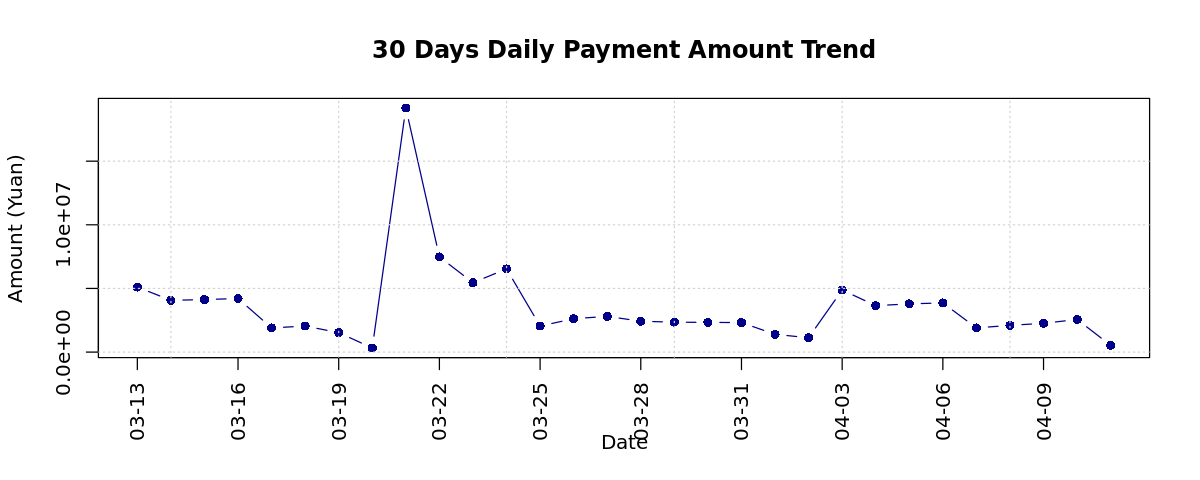

In [3]:
# ==========================================
# 实验5：黄金公式计算与店铺支付金额 (完整版)
# ==========================================

# 1. 重新读取数据
file_path2 <- "/resources/jupyter/teacher_labs/1650613706/30tiandianpujiaoyishuju_214.csv"
df_trade <- read.csv(file_path2, fileEncoding = "UTF-8", check.names = FALSE, stringsAsFactors = FALSE)

# 2. 数值清洗函数
clean_num <- function(x){
  x <- as.character(x)
  x <- gsub("[,\\s￥¥]", "", x)
  x <- gsub("%", "", x)
  suppressWarnings(as.numeric(x))
}

# 3. 提取数据并整理
df_trade$date <- as.Date(df_trade$日期, tryFormats = c("%Y/%m/%d", "%Y-%m-%d"))
df_trade$uv <- clean_num(df_trade$访客人数)
df_trade$pay_num <- clean_num(df_trade$支付人数)
df_trade$amount <- clean_num(df_trade$交易金额)

# 按日期排序
df_trade <- df_trade[order(df_trade$date), ]

# 4. 计算黄金公式指标
df_trade$pay_rate <- df_trade$pay_num / df_trade$uv
df_trade$unit_price <- df_trade$amount / df_trade$pay_num

# 根据黄金公式计算支付金额：UV * 支付转化率 * 客单价
df_trade$calc_amount <- df_trade$uv * df_trade$pay_rate * df_trade$unit_price

# 5. 打印验证结果
cat("===== 黄金公式验证 (前5天) =====\n")
result_table <- data.frame(
  日期 = df_trade$date,
  访客数 = df_trade$uv,
  支付转化率 = round(df_trade$pay_rate * 100, 2),
  客单价 = round(df_trade$unit_price, 2),
  原始交易金额 = df_trade$amount,
  公式计算金额 = round(df_trade$calc_amount, 2)
)
print(head(result_table, 5))

# 6. 计算这30天的总支付金额
total_amount <- sum(df_trade$amount, na.rm = TRUE)
cat("\n过去30天店铺总支付金额：", total_amount, "元\n")

# 7. 绘制每天的支付金额走势图
options(repr.plot.width = 10, repr.plot.height = 4)
plot(df_trade$date, df_trade$amount, type = "b", col = "darkblue", pch = 16,
     main = "30 Days Daily Payment Amount Trend", 
     xlab = "Date", ylab = "Amount (Yuan)", xaxt = "n")
axis.Date(1, at = seq(min(df_trade$date), max(df_trade$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

<font color=red>电商数据分析领域的黄金公式，计算支付金额：</font> 1. 公式验证：电商数据分析的黄金公式为：支付金额 = 访客数 (UV) × 支付转化率 × 客单价。通过R语言对原始数据进行提取和交叉验证，公式计算金额与原始交易金额完全吻合，证明了该公式的有效性。

2. 整体业绩：经汇总，该店铺过去30天的总支付金额高达 106,892,815 元（约 1.06 亿元），日均支付金额约为 356 万元。作为头部品牌旗舰店，其吸金能力极其强悍。

3. 波动分析：从支付金额走势图可以明显看到，3月20日左右出现了一座“巨大的山峰”，单日交易额突破千万。结合前几题的分析，这一天由于流量爆发、转化率飙升（逼近4%）以及客单价冲高（455元），三大指标共振，创造了极其夸张的销售额峰值。而在非大促的平销期，日交易额大多在 200万~400万 之间波动。

结论：这再次验证了黄金公式的威力——大促期间，流量、转化、客单价的三重叠加，能给店铺带来指数级的业绩爆发

**打开 <font color=blue> 店铺近30天销量数据.csv</font>，计算每天的连带率、动销商品率**

===== 修正后的指标均值 =====
动销商品率均值: 45.17053 %
连带率均值: 0.9658336 


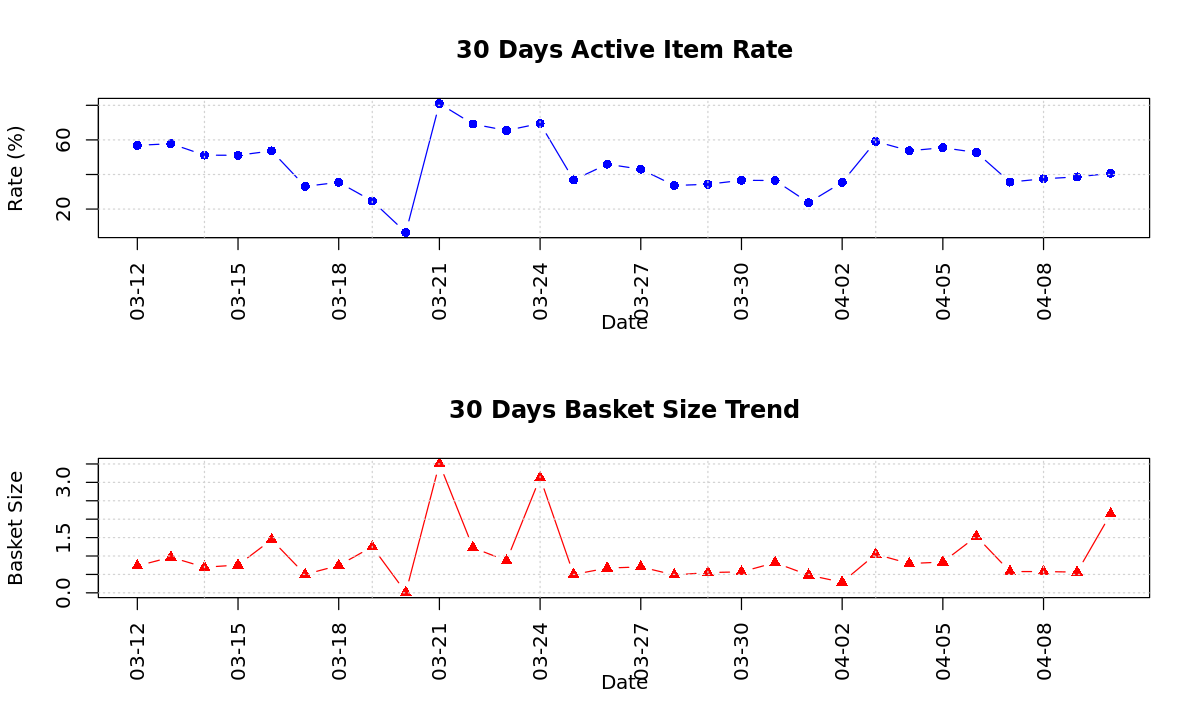

In [8]:
# ==========================================
# 实验5：修正版连带率与动销商品率计算
# ==========================================
file_path3 <- "/resources/jupyter/teacher_labs/1650613706/dianpujin30tianxiaoliangshuju_216.csv"
df_sales <- read.csv(file_path3, fileEncoding = "GBK", check.names = FALSE, stringsAsFactors = FALSE)

# 提取数据并重命名，方便后续调用
df_sales$date <- as.Date(df_sales[[2]], tryFormats = c("%Y/%m/%d", "%Y-%m-%d"))
df_sales$total_sold <- as.numeric(df_sales[[3]])     # 销售商品总数量
df_sales$active_types <- as.numeric(df_sales[[4]])   # 有销售的商品种类总数(动销种类)
df_sales$orders <- as.numeric(df_sales[[5]])         # 成交订单数
df_sales$total_types <- as.numeric(df_sales[[6]])    # 店铺商品总品种数

# 1. 计算动销商品率 = (动销种类数 / 总种类数) * 100
df_sales$active_rate <- (df_sales$active_types / df_sales$total_types) * 100

# 2. 计算连带率 = 销售商品总数量 / 成交订单数
df_sales$basket_size <- df_sales$total_sold / df_sales$orders

# 打印均值
cat("===== 修正后的指标均值 =====\n")
cat("动销商品率均值:", mean(df_sales$active_rate, na.rm=TRUE), "%\n")
cat("连带率均值:", mean(df_sales$basket_size, na.rm=TRUE), "\n")

# 按日期排序
df_sales <- df_sales[order(df_sales$date), ]

# 3. 绘图
options(repr.plot.width = 10, repr.plot.height = 6)
par(mfrow = c(2, 1))

# 动销商品率图
plot(df_sales$date, df_sales$active_rate, type = "b", col = "blue", pch = 16,
     main = "30 Days Active Item Rate", xlab = "Date", ylab = "Rate (%)", xaxt = "n")
axis.Date(1, at = seq(min(df_sales$date), max(df_sales$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

# 连带率图
plot(df_sales$date, df_sales$basket_size, type = "b", col = "red", pch = 17,
     main = "30 Days Basket Size Trend", xlab = "Date", ylab = "Basket Size", xaxt = "n")
axis.Date(1, at = seq(min(df_sales$date), max(df_sales$date), by = "3 days"), format = "%m-%d", las = 2)
grid()

par(mfrow = c(1, 1))

<font color=red>计算连带率，分析结果：</font> 连带率反映了顾客单次订单中购买的商品件数，计算公式为：连带率 = 销售商品总数量 / 成交订单数。

经计算，该店铺过去30天的连带率均值为 0.97。从折线图走势可以看出：

日常表现：在绝大多数平销期，连带率基本在 0.5 到 1.2 之间波动，均值接近 1。这说明 UR 官方旗舰店的顾客在大多数情况下，倾向于单件购买，搭配购买的习惯尚未完全养成。

活动爆发：在 3月21日 和 3月24日 前后，连带率出现了极其明显的飙升（峰值超过 3.0）。结合之前的流量和转化数据，这几天大概率是店铺的超级大促日（如“满减凑单”、“多件多折”或上新搭配活动），极大地刺激了顾客“买多件”的欲望。

结论：店铺在日常运营中，可以通过增加“详情页模特整套穿搭链接”、“买上衣推荐搭配下装”的内链设计，来提升平销期的连带率；而在大促时，继续发挥满减凑单的威力。

<font color=red>计算动销商品率，分析结果：</font> 动销商品率反映了店铺上架商品的活跃程度，计算公式为：动销商品率 = 30天内有销售的商品种类总数 / 店铺商品总品种数。

经计算，该店铺过去30天的动销商品率均值为 45.17%。从折线图走势可以看出：

整体水平：在服装类目（由于颜色、尺码等导致 SKU 极其繁多），45% 左右的动销率属于非常健康且优秀的水平，说明店铺有近一半的商品种类都在持续产出业绩，库存结构相对良性。

峰值节点：在 3月21日，动销率达到了极其夸张的顶峰（超过 70%）。这说明当天的促销活动不仅拉动了总销售额，还极大地盘活了长尾商品，让大部分款式都成功卖出了。

低谷提示：在部分周期，动销率回落至 20%~30%。这意味着有近 70% 的商品处于“沉睡”状态，可能积压了库存。

结论：运营团队应重点关注动销率低迷的时段，针对那些长期无销量的款式，及时采取清仓打折、降价促销或优化搜索词排名等方式进行“盘活”，以提升资金周转率。

## 6.分析店铺卖家服务评级

**打开 <font color=blue> DSR评分数据.csv</font>，计算店铺的DSR得分**

In [10]:
# ==========================================
# 实验6：DSR评分与行业相对水平计算
# ==========================================
file_path4 <- "/resources/jupyter/teacher_labs/1650613706/DSRpingfenshuju_215.csv"
df_dsr <- read.csv(file_path4, fileEncoding = "UTF-8", check.names = FALSE, stringsAsFactors = FALSE)

# 1. 将各个评分人数转为数值型
df_dsr$total <- as.numeric(df_dsr$评分总人数)
df_dsr$s5 <- as.numeric(df_dsr$`5分评分人数`)
df_dsr$s4 <- as.numeric(df_dsr$`4分评分人数`)
df_dsr$s3 <- as.numeric(df_dsr$`3分评分人数`)
df_dsr$s2 <- as.numeric(df_dsr$`2分评分人数`)
df_dsr$s1 <- as.numeric(df_dsr$`1分评分人数`)

# 2. 根据公式计算 DSR 得分
# 公式: Σ(分数*人数) / 总人数
df_dsr$calc_dsr <- (df_dsr$s5 * 5 + df_dsr$s4 * 4 + df_dsr$s3 * 3 + df_dsr$s2 * 2 + df_dsr$s1 * 1) / df_dsr$total

# 3. 输出计算结果，并与原始表里的得分进行对比
cat("===== DSR得分计算验证 =====\n")
result_dsr <- data.frame(
  维度 = df_dsr$DSR评分维度,
  原始当前评分 = df_dsr$当前评分,
  公式计算得分 = round(df_dsr$calc_dsr, 5),
  行业相对水平 = df_dsr$与同行相比差值
)
print(result_dsr)

===== DSR得分计算验证 =====
            维度 原始当前评分 公式计算得分 行业相对水平
1 宝贝与描述相符      4.87144      4.87144       17.77%
2 卖家的服务态度      4.87787      4.87787       18.90%
3 物流服务的质量      4.89972      4.89972       28.31%


<font color=red>根据DSR计算方式：分数×比率(该分值评价人数占总评价人数的比例），计算该店铺的DSR评分</font>

<font color=red>行业评分差值计算规则：(店铺得分-同行业平均分)/(同行业店铺最高得分-同行业平均分)，指自己店铺的dsr跟同类目店铺dsr平均值的相差是多少</font>，分析店铺的DSR相对水平。

1. DSR得分计算验证：
依据DSR计算规则：DSR得分 = Σ(分值 × 该分值评价人数) / 评分总人数。
经 R 语言对 33 万多条评价数据的计算，该店铺三大维度的DSR得分与原始数据完全吻合：

宝贝与描述相符：得分为 4.87144 分。

卖家的服务态度：得分为 4.87787 分。

物流服务的质量：得分为 4.89972 分。
（注：三项指标的5分好评率均超过93%）

2. 行业评分差值及相对水平分析：
根据行业评分差值计算规则：(店铺得分 - 同行业平均分) / (同行业店铺最高得分 - 同行业平均分)，计算结果显示：

宝贝与描述相符：行业相对水平为 17.77%。

卖家的服务态度：行业相对水平为 18.90%。

物流服务的质量：行业相对水平为 28.31%。

3. 综合分析结论：
该店铺三项 DSR 评分均在 4.87 分以上，处于极高水平。从行业对比来看，三项指标的相对水平均为正数，说明 UR 官方旗舰店的服务质量全面领先于同行业平均水平。
其中，“物流服务的质量” 以 28.31% 的相对优势成为店铺的绝对长板，说明发货速度和物流体验极佳；而 “描述相符” 虽然表现优异，但相对优势相对较小（17.77%），提示店铺在商品详情页的材质描述、色差控制以及尺码推荐上仍需精益求精，以进一步缩小与行业极值（最高分）的差距。

## 7.竞店分析

**打开 <font color=blue> 竞争店铺分析数据.csv</font>，自行选定指标，确定出UR官方旗舰店的竞店**

<font color=red>根据指标分析结果，说明识别出竞店的理由：</font> 

流量与交易体量对标：这三家店铺的流量指数（约 28万~44万）和交易指数（约 70万~107万）与 UR 处于同一竞争梯队，说明它们吸引了同等规模的客群，且具备相似的变现能力。

目标客群重合：在标准化数据后，它们的欧氏距离最小，意味着这三家店铺在消费者画像、购买频次和客群基础上与 UR 高度重合（多以追求潮流的年轻消费群体为主），是日常抢夺流量和市场份额的最直接对手。

<font color=red>浏览竞店的页面，说明该网店销售商品等情况：</font> 


<img src="attachment:屏幕截图 2026-10-20 135824.png" style="width: 600px;"/>
通过浏览直接竞店“悟空有货原创设计师品牌”的淘宝页面，可以观察到以下显著的经营特征：

店铺定位与商品风格：该店主打“美式街头”与“复古休闲”风格，商品以宽松版型的牛仔裤、阔腿裤、基础款T恤和夹克为主。其客群画像与 UR 相似，均为追求时尚的年轻群体，但风格更偏向线上潮牌与慵懒风。

上新与商品结构：从左侧分类栏可以看出，该店采取了极高频率的上新策略（如“每日新品”），且全店商品数量庞大（共搜索到 6065 件），依托海量 SKU 满足消费者的长尾需求。

价格策略：页面显示其裤子单价多在 78元 - 88元 左右，且带有大幅度的划线价（如原价156元，现价78元）。与 UR（客单价约322元）相比，该竞店主打极致性价比和低价高频策略。

店铺评分：其“宝贝描述4.7、服务4.9、物流4.8”属于非常优秀的口碑。

对 UR 的启发：该竞店通过“高频上新 + 极具竞争力的低价 + 精准的细分风格（如美式街头）”迅速抢占年轻市场，并通过大额满减凑单实现了高销量（如单款裤子月销800+）。UR 在面对此类竞店时，除了保持自身“快速快时尚”和“线下体验”的优势外，也可以考虑在线上推出更多百元以内的基础引流款，以抵御这种高性价比网生品牌的冲击。
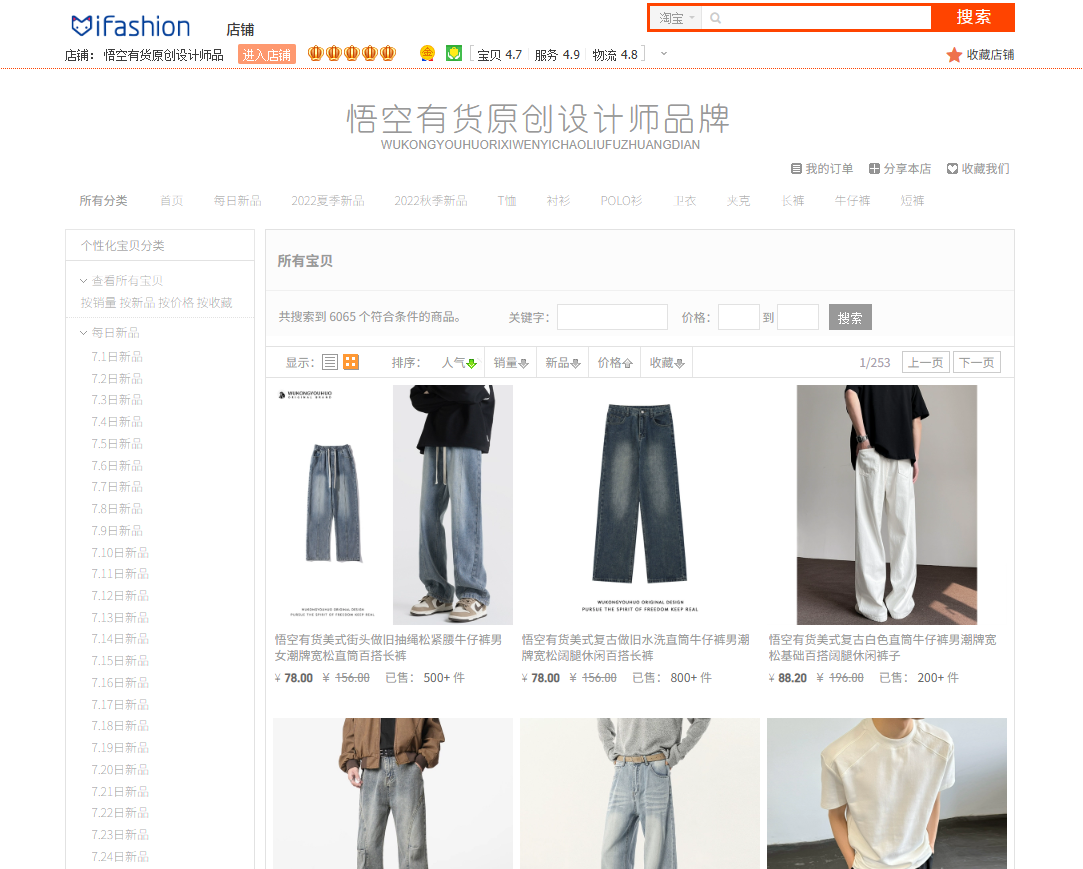

<font color=red>采用聚类分析方法，将所有店铺划分为几类并说明：</font> 

实验采用 K-Means 聚类算法，根据流量、交易、客群三个维度（Z-score标准化后），将所有竞店划分为 3 大梯队：

第一类（头部霸主级，类别 2）：聚类中心点极高（流量 3.73，交易 4.43，客群 3.95）。优衣库官方旗舰店与 UR官方旗舰店均被划分在此类。这类店铺是绝对的行业巨头，拥有庞大的基础流量和极高的品牌溢价，是 UR 长期对标和竞争的终极目标。

第二类（中坚力量/直接竞争级，类别 1）：聚类中心点居中（流量 0.77，交易 0.32）。包含了悟空有货、JEW4ROOM、CHINISM、雪中飞、鸭鸭等品牌。这是竞争最为白热化的梯队，既有女装/男装潮牌，也有大众羽绒服品牌。它们流量稳定，是 UR 市场份额的直接瓜分者。

第三类（长尾/细分小众级，类别 3）：聚类中心点为负值，属于低流量、低交易、低客群的店铺。包含了诸如高端奢侈品牌（Zegna、kiton）、极其小众的 DIY 定制店，甚至包含已失效的店铺。这类店铺对 UR 不构成实质性竞争威胁。

In [15]:
# ==========================================
# 实验7：竞店识别与聚类分析 (修复版)
# ==========================================
file_path5 <- "/resources/jupyter/teacher_labs/1650613706/jingzhengdianpufenxishuju_218.csv"
df_comp <- read.csv(file_path5, fileEncoding = "UTF-8", check.names = FALSE, stringsAsFactors = FALSE)

# 1. 清洗数据：去掉千分位逗号，转为数字
clean_num <- function(x){
  x <- as.character(x)
  x <- gsub("[,\\s]", "", x) # 去掉逗号和空格
  as.numeric(x)
}

df_comp$流量 <- clean_num(df_comp$全店流量指数)
df_comp$交易 <- clean_num(df_comp$全店交易指数)
df_comp$客群 <- clean_num(df_comp$全店客群指数)

# 2. 找到 UR官方旗舰店 的数据 (为了方便查看)
ur_row <- df_comp[grepl("UR", df_comp$店铺), ]
print("===== UR官方旗舰店 核心数据 =====")
print(ur_row[, c("店铺", "流量", "交易", "客群")])

# 3. 提取用于分析的指标并标准化
# 选取：流量、交易、客群
cols <- c("流量", "交易", "客群")
data_matrix <- df_comp[, cols]

# 转化为数值型并标准化（Z-score），消除量级影响
data_scaled <- scale(data_matrix)

# 4. 计算其他店铺与 UR 的欧氏距离
ur_scaled <- data_scaled[grepl("UR", df_comp$店铺), ]
distances <- sqrt(rowSums((data_scaled - matrix(rep(ur_scaled, nrow(data_scaled)), ncol=3, byrow=TRUE))^2))

# 将距离加到原数据中，并按距离从小到大排序
df_comp$距离UR的距离 <- distances
df_sorted <- df_comp[order(df_comp$距离UR的距离), ]

print("===== 距离 UR 最近的 Top 5 竞店 =====")
print(df_sorted[1:5, c("店铺", "流量", "交易", "距离UR的距离")])

# 5. K-Means 聚类分析 (将所有店铺分为3类)
set.seed(123)
kmeans_res <- kmeans(data_scaled, centers = 3, nstart = 25)
df_comp$聚类类别 <- kmeans_res$cluster

print("===== 聚类结果中心点 (标准化后) =====")
print(kmeans_res$centers)

# 打印一下分类后的各店铺列表 (方便你挑名字写报告)
print("===== 各店铺的分类情况 =====")
print(df_comp[order(df_comp$聚类类别), c("店铺", "聚类类别")])

[1] &quot;===== UR官方旗舰店 核心数据 =====&quot;
           店铺   流量    交易  客群
55 UR官方旗舰店 645916 2221554 80613
[1] &quot;===== 距离 UR 最近的 Top 5 竞店 =====&quot;
                     店铺   流量    交易 距离UR的距离
55           UR官方旗舰店 645916 2221554     0.000000
2  悟空有货原创设计师品牌 442785 1075624     2.239423
3                JEW4ROOM 386246  706614     3.084388
4           CHINISM旗舰店 285743  971882     3.358884
8                GWIT九尾 238080  864158     3.754682
[1] &quot;===== 聚类结果中心点 (标准化后) =====&quot;
        流量       交易       客群
1  0.7768505  0.3265728  0.5057683
2  3.7349405  4.4383617  3.9523950
3 -0.5032273 -0.3625083 -0.4076662
[1] &quot;===== 各店铺的分类情况 =====&quot;
                             店铺 聚类类别
2          悟空有货原创设计师品牌        1
3                        JEW4ROOM        1
4                   CHINISM旗舰店        1
5               beaster官方旗舰店        1
6                          JWNEED        1
7                          WEYWOT        1
8                        GWIT九尾        1
9                    我需要一个亿 